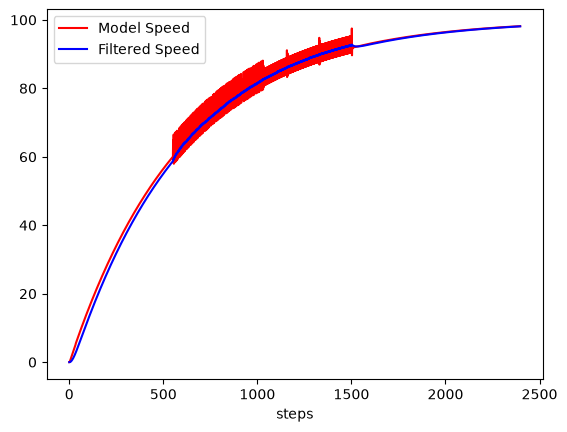

In [7]:
#
# filter_ball.py
#
import arslabrobotics as ar
import numpy as np

data = np.loadtxt("ball_data.txt")
(rows, _) = data.shape

alpha = 0.95
fltr = ar.identification.ARXModel([-alpha], [1 - alpha])
# y(k) = alpha * y(k-1) + (1 - alpha) * u(k) 

dp = ar.data.DataPlotter()
dp.set_x("steps")
dp.add_y("speed_m", "Model Speed")
dp.add_y("speed_f", "Filtered Speed")

t = 0
for i in range(rows):
    y_measure = data[i, 1]
    y_filtered = fltr.evaluate(y_measure)
    dp.append_x(t)
    dp.append_y("speed_m", y_measure)
    dp.append_y("speed_f", y_filtered)
    t += 1

dp.plot()
